<a href="https://colab.research.google.com/github/mitadeon/tugas-machine-learning/blob/main/Analisis_Paddy_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis dan Pemodelan Machine Learning — Paddy Dataset

Notebook ini menyusun alur lengkap dari **load data, pemeriksaan data, preprocessing, outlier, missing values, EDA, hingga pemodelan regresi** untuk memprediksi `Paddy yield(in Kg)`.

**Sebelum mulai**
- Letakkan file `paddy+dataset.zip` (atau file `paddydataset.csv` hasil ekstraksi) di folder yang sama dengan notebook.
- Jalankan sel secara berurutan dari atas ke bawah.
- Model ini memprediksi hasil padi dalam kilogram. Hasil evaluasi adalah estimasi pada data uji, bukan jaminan hasil panen di lapangan.
- Dataset yang disediakan berisi data pertanian; nilai ekstrem tidak otomatis salah. Karena itu, outlier akan diperiksa dan dilaporkan, bukan langsung dihapus.

## 1. Import library

**Sebelum dijalankan:** kita perlu pustaka untuk membaca dan mengolah data, visualisasi, serta membangun dan mengevaluasi model.

**Sesudah dijalankan:** jika tidak ada error, seluruh pustaka siap digunakan. Jika ada `ModuleNotFoundError`, instal paket yang disebutkan menggunakan `%pip install nama_paket`.

In [1]:
import os
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Load dataset

**Sebelum dijalankan:** kode mencari `paddydataset.csv` atau `paddy+dataset.zip` di folder kerja notebook. Jika CSV berada di dalam ZIP, kode akan membacanya langsung tanpa perlu mengekstrak manual.

**Sesudah dijalankan:** `df` berisi tabel data mentah. Periksa pesan nama file dan ukuran data. Jika file tidak ditemukan, pindahkan ZIP/CSV ke folder notebook atau ubah `DATA_PATH`.

In [2]:
DATA_PATH = Path(".")
csv_candidates = list(DATA_PATH.glob("*.csv"))
zip_candidates = list(DATA_PATH.glob("*.zip"))

if csv_candidates:
    data_file = csv_candidates[0]
    df = pd.read_csv(data_file)
    print(f"CSV dimuat: {data_file}")
elif zip_candidates:
    # Cari file ZIP yang berisi CSV
    chosen_zip = None
    csv_member = None
    for zip_path in zip_candidates:
        with zipfile.ZipFile(zip_path) as zf:
            members = [name for name in zf.namelist() if name.lower().endswith(".csv")]
            if members:
                chosen_zip, csv_member = zip_path, members[0]
                with zf.open(csv_member) as f:
                    df = pd.read_csv(f)
                break
    if chosen_zip is None:
        raise FileNotFoundError("ZIP ditemukan, tetapi tidak berisi file CSV.")
    print(f"CSV dimuat dari: {chosen_zip} → {csv_member}")
else:
    raise FileNotFoundError(
        "Tidak menemukan CSV/ZIP. Letakkan paddydataset.csv atau paddy+dataset.zip "
        "di folder yang sama dengan notebook."
    )

print("Ukuran data (baris, kolom):", df.shape)
display(df.head())

CSV dimuat: paddydataset.csv
Ukuran data (baris, kolom): (2789, 45)


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,250.0,61.0,64.0,18.5,34,16.0,30,15.5,31.0,16.0,33.0,4,10,8,10,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,250.0,61.0,64.0,19.5,34,18.5,35,17.0,32.5,16.0,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60.0,65.0,20.0,35,18.0,30,17.5,33.5,18.0,33.0,4,12,4,12,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60.0,65.0,19.0,33,17.0,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18.0,34.0,16.5,35.0,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


**Interpretasi setelah load:** setiap baris adalah satu observasi pada dataset. Kolom `Paddy yield(in Kg)` dipilih sebagai target yang ingin diprediksi; kolom lainnya menjadi kandidat fitur.

## 3. Memahami struktur data

**Sebelum dijalankan:** kita belum mengetahui tipe data, jumlah baris/kolom, maupun contoh nilai setiap kolom.

**Sesudah dijalankan:** `info()` menunjukkan tipe data dan kelengkapan kolom; `describe()` merangkum statistik numerik. Gunakan hasil ini untuk menemukan tipe data yang tidak sesuai dan rentang nilai yang perlu diperiksa.

In [3]:
print("=== INFO DATA ===")
df.info()

print("\n=== 5 BARIS PERTAMA ===")
display(df.head())

print("\n=== STATISTIK NUMERIK ===")
display(df.describe().T)

print("\n=== JUMLAH NILAI UNIK ===")
display(df.nunique().sort_values().to_frame("jumlah_nilai_unik"))

=== INFO DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   object 
 2   Variety                             2789 non-null   object 
 3   Soil Types                          2789 non-null   object 
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   object 
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days              

,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,250.0,61.0,64.0,18.5,34,16.0,30,15.5,31.0,16.0,33.0,4,10,8,10,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167.0,250.0,61.0,64.0,19.5,34,18.5,35,17.0,32.5,16.0,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60.0,65.0,20.0,35,18.0,30,17.5,33.5,18.0,33.0,4,12,4,12,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60.0,65.0,19.0,33,17.0,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18.0,34.0,16.5,35.0,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044



=== STATISTIK NUMERIK ===


,count,mean,std,min,25%,50%,75%,max
Hectares,2789.0,3.717461,1.437777,1.00,3.00,4.00,5.00,6.00
Seedrate(in Kg),2789.0,92.936536,35.944420,25.00,75.00,100.00,125.00,150.00
LP_Mainfield(in Tonnes),2789.0,46.468268,17.972210,12.50,37.50,50.00,62.50,75.00
Nursery area (Cents),2789.0,74.349229,28.755536,20.00,60.00,80.00,100.00,120.00
LP_nurseryarea(in Tonnes),2789.0,3.717461,1.437777,1.00,3.00,4.00,5.00,6.00
DAP_20days,2789.0,148.698458,57.511072,40.00,120.00,160.00,200.00,240.00
Weed28D_thiobencarb,2789.0,7.434923,2.875554,2.00,6.00,8.00,10.00,12.00
Urea_40Days,2789.0,100.854729,39.006885,27.13,81.39,108.52,135.65,162.78
Potassh_50Days,2789.0,38.587250,14.924123,10.38,31.14,41.52,51.90,62.28
Micronutrients_70Days,2789.0,55.761922,21.566652,15.00,45.00,60.00,75.00,90.00



=== JUMLAH NILAI UNIK ===


,jumlah_nilai_unik
Soil Types,2
Nursery,2
Variety,3
30DRain( in mm),3
51_70DRain(in mm),3
30_50DAI(in mm),3
30_50DRain( in mm),3
30DAI(in mm),3
71_105DRain(in mm),3
71_105DAI(in mm),3


## 4. Pemeriksaan kualitas data

**Sebelum dijalankan:** duplikasi, nilai kosong, dan kolom konstan belum diperiksa.

**Sesudah dijalankan:** tabel menampilkan jumlah missing values, duplikasi baris, dan kolom yang hanya memiliki satu nilai unik. Kolom konstan biasanya tidak membantu model; jangan menghapus kolom sebelum memahami maknanya.

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
print("=== MISSING VALUES PER KOLOM ===")
display(missing[missing > 0].to_frame("jumlah_missing") if (missing > 0).any()
        else pd.DataFrame({"status": ["Tidak ada missing value pada data mentah"]}))

print("Jumlah baris duplikat:", df.duplicated().sum())
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Kolom konstan:", constant_cols if constant_cols else "Tidak ada")

=== MISSING VALUES PER KOLOM ===


,status
0,Tidak ada missing value pada data mentah


Jumlah baris duplikat: 451
Kolom konstan: Tidak ada


## 5. Pembersihan dasar

**Sebelum dijalankan:** duplikasi persis dapat membuat observasi yang sama terhitung berulang. Nilai kosong perlu ditangani, tetapi pengisian nilai sebaiknya dipelajari dari data latih agar tidak terjadi kebocoran informasi.

**Sesudah dijalankan:** baris duplikat persis dihapus. Nilai kosong yang tersisa tidak diisi secara manual di sini; imputasi akan dilakukan di pipeline setelah pembagian data train/test.

In [5]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Baris sebelum: {n_before:,}")
print(f"Baris setelah menghapus duplikat: {len(df):,}")
print(f"Duplikat yang dihapus: {n_before - len(df):,}")

Baris sebelum: 2,789
Baris setelah menghapus duplikat: 2,338
Duplikat yang dihapus: 451


## 6. Analisis outlier dengan metode IQR

**Sebelum dijalankan:** nilai ekstrem belum ditandai. Metode IQR menandai nilai di bawah `Q1 − 1.5×IQR` atau di atas `Q3 + 1.5×IQR`.

**Sesudah dijalankan:** tabel memberi jumlah dan persentase nilai yang terindikasi outlier untuk tiap kolom numerik. Ini hanya penanda statistik, bukan bukti kesalahan. Pada data pertanian, nilai tinggi/rendah bisa valid, jadi kita tidak menghapusnya secara otomatis.

In [6]:
numeric_all = df.select_dtypes(include=np.number)
outlier_rows = []
for col in numeric_all.columns:
    q1, q3 = numeric_all[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        count = 0
    else:
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        count = int(((numeric_all[col] < lower) | (numeric_all[col] > upper)).sum())
    outlier_rows.append({
        "kolom": col, "jumlah_outlier_IQR": count,
        "persentase_%": round(count / len(df) * 100, 2)
    })
outlier_report = pd.DataFrame(outlier_rows).sort_values("jumlah_outlier_IQR", ascending=False)
display(outlier_report.head(20))

,kolom,jumlah_outlier_IQR,persentase_%
29,Inst Wind Speed_D61_D90(in Knots),360,15.4
1,Seedrate(in Kg),0,0.0
2,LP_Mainfield(in Tonnes),0,0.0
3,Nursery area (Cents),0,0.0
0,Hectares,0,0.0
4,LP_nurseryarea(in Tonnes),0,0.0
5,DAP_20days,0,0.0
7,Urea_40Days,0,0.0
6,Weed28D_thiobencarb,0,0.0
9,Micronutrients_70Days,0,0.0


## 7. Exploratory Data Analysis (EDA)

**Sebelum dijalankan:** pola distribusi, perbedaan hasil panen, dan hubungan antarnilai belum terlihat.

**Sesudah dijalankan:** histogram memperlihatkan distribusi target; boxplot membantu melihat rentang dan nilai ekstrem; grafik kategori memperlihatkan rata-rata hasil panen menurut varietas dan jenis tanah. Grafik korelasi hanya memakai kolom numerik.

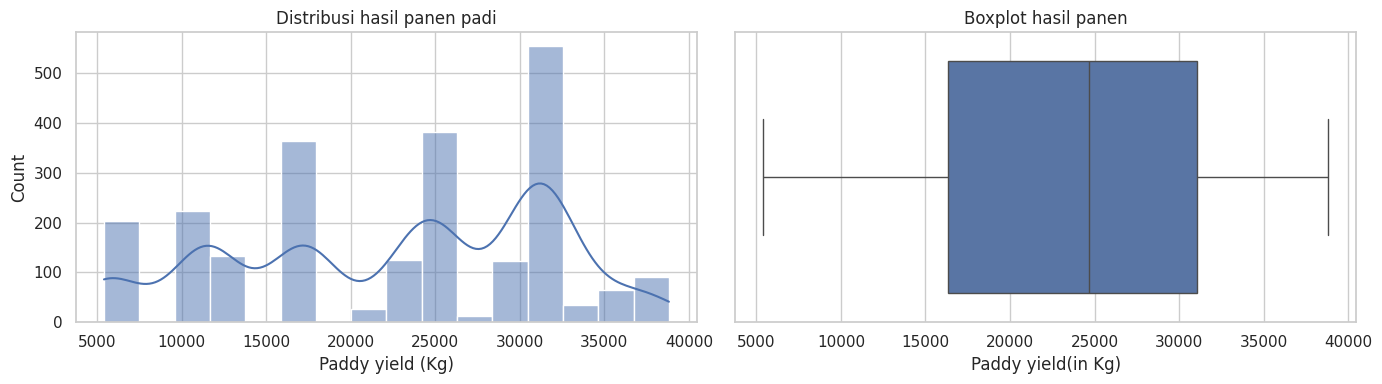

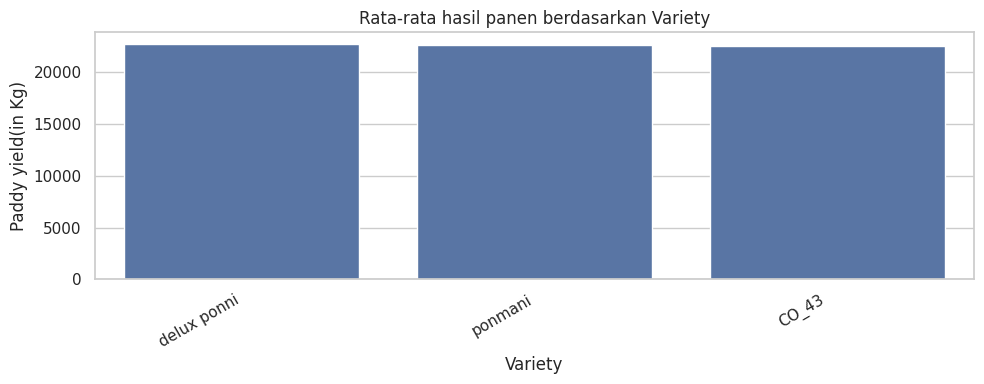

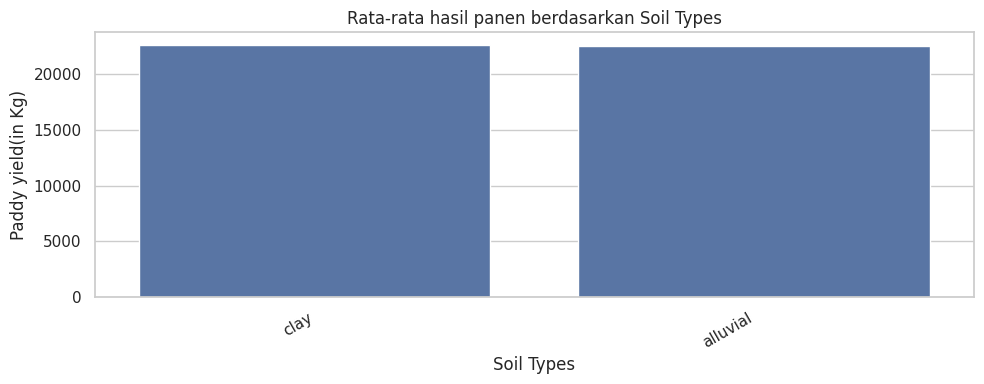

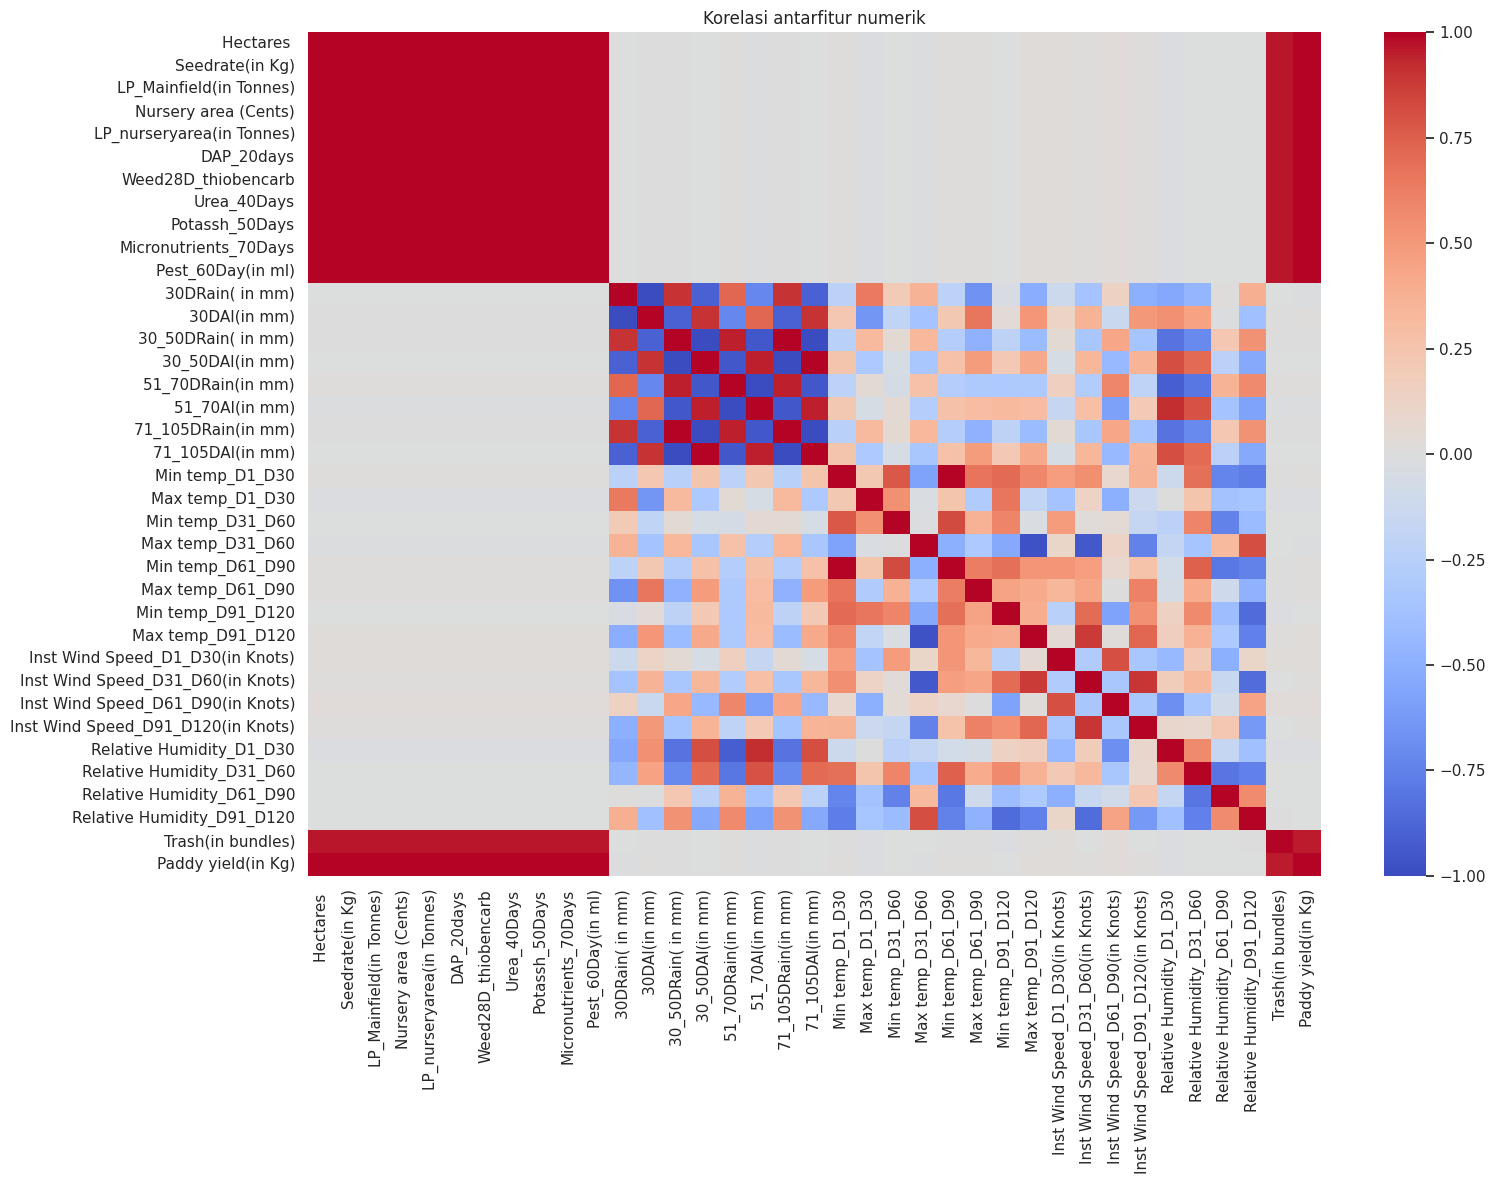

Ringkasan target:


,Paddy yield (Kg)
count,2338.000000
mean,22610.117622
std,9265.184949
min,5410.000000
25%,16359.000000
50%,24644.000000
75%,31035.000000
max,38814.000000


In [7]:
target = "Paddy yield(in Kg)"
if target not in df.columns:
    raise KeyError(f"Kolom target '{target}' tidak ditemukan. Periksa nama kolom.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[target], kde=True, ax=axes[0])
axes[0].set_title("Distribusi hasil panen padi")
axes[0].set_xlabel("Paddy yield (Kg)")
sns.boxplot(x=df[target], ax=axes[1])
axes[1].set_title("Boxplot hasil panen")
plt.tight_layout()
plt.show()

for col in ["Variety", "Soil Types"]:
    if col in df.columns:
        plt.figure(figsize=(10, 4))
        order = df.groupby(col)[target].mean().sort_values(ascending=False).index
        sns.barplot(data=df, x=col, y=target, order=order, errorbar=None)
        plt.title(f"Rata-rata hasil panen berdasarkan {col}")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Korelasi antarfitur numerik")
plt.tight_layout()
plt.show()

print("Ringkasan target:")
display(df[target].describe().to_frame("Paddy yield (Kg)"))

## 8. Menyiapkan fitur dan target

**Sebelum dijalankan:** model belum mengetahui kolom mana yang diprediksi dan kolom mana yang digunakan sebagai input.

**Sesudah dijalankan:** `X` berisi semua kolom selain target, sedangkan `y` berisi hasil panen. Data dibagi menjadi 80% data latih dan 20% data uji. Pembagian dilakukan sebelum imputasi dan encoding agar informasi dari data uji tidak bocor ke proses pelatihan.

In [8]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

print("Jumlah fitur:", X.shape[1])
print("Fitur numerik:", len(numeric_cols))
print("Fitur kategorikal:", len(categorical_cols))
print(f"Data latih: {X_train.shape[0]} baris")
print(f"Data uji:   {X_test.shape[0]} baris")

Jumlah fitur: 44
Fitur numerik: 36
Fitur kategorikal: 8
Data latih: 1870 baris
Data uji:   468 baris


## 9. Preprocessing dan pemodelan

**Sebelum dijalankan:** sebagian model tidak dapat menerima teks kategori atau nilai kosong. Karena itu, pipeline akan:
1. Mengisi nilai numerik kosong dengan median.
2. Mengisi kategori kosong dengan modus.
3. Melakukan standardisasi fitur numerik.
4. Mengubah kategori menjadi kolom biner menggunakan One-Hot Encoding.
5. Melatih Random Forest Regressor.

**Sesudah dijalankan:** model terlatih dan siap memprediksi data uji. Pipeline memastikan langkah preprocessing yang sama diterapkan pada data latih maupun data uji. Random Forest dipakai sebagai baseline yang mampu menangkap hubungan nonlinier.

In [9]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Pelatihan selesai. Prediksi data uji berhasil dibuat.")

Pelatihan selesai. Prediksi data uji berhasil dibuat.


## 10. Evaluasi model

**Sebelum dijalankan:** kita belum tahu seberapa dekat prediksi model dengan hasil panen aktual.

**Sesudah dijalankan:** metrik berikut mengukur performa pada data uji yang tidak digunakan untuk melatih model:
- **MAE:** rata-rata kesalahan absolut, dalam kilogram; makin kecil makin baik.
- **RMSE:** memberi penalti lebih besar pada kesalahan besar, dalam kilogram; makin kecil makin baik.
- **R²:** proporsi variasi target yang dijelaskan model; makin mendekati 1 umumnya makin baik. Nilai negatif berarti model lebih buruk daripada prediksi sederhana berupa rata-rata target pada data uji.

In [10]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metrik": ["MAE (Kg)", "RMSE (Kg)", "R²"],
    "Nilai": [mae, rmse, r2]
})
display(metrics)

,Metrik,Nilai
0,MAE (Kg),685.838857
1,RMSE (Kg),952.580774
2,R²,0.989401


## 11. Membandingkan hasil aktual dan prediksi

**Sebelum dijalankan:** angka metrik belum menunjukkan contoh kesalahan pada tiap observasi.

**Sesudah dijalankan:** tabel membandingkan hasil aktual, hasil prediksi, dan selisihnya. Grafik aktual vs prediksi yang mendekati garis diagonal menunjukkan prediksi yang lebih dekat dengan nilai aktual.

,Aktual (Kg),Prediksi (Kg),Error absolut (Kg)
0,31555,30509.121701,1045.878299
1,17949,17473.070821,475.929179
2,30795,31415.679464,620.679464
3,5836,5716.914924,119.085076
4,30285,31294.087165,1009.087165
5,17169,17085.496623,83.503377
6,32050,31072.926880,977.073120
7,25452,24853.205525,598.794475
8,11672,11626.528713,45.471287
9,11710,11471.348707,238.651293


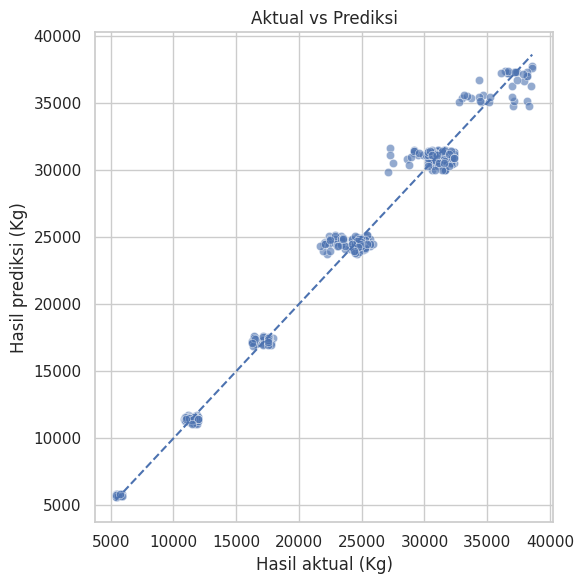

In [11]:
comparison = pd.DataFrame({
    "Aktual (Kg)": y_test.to_numpy(),
    "Prediksi (Kg)": y_pred,
})
comparison["Error absolut (Kg)"] = (comparison["Aktual (Kg)"] - comparison["Prediksi (Kg)"]).abs()
display(comparison.head(15))

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Hasil aktual (Kg)")
plt.ylabel("Hasil prediksi (Kg)")
plt.title("Aktual vs Prediksi")
plt.tight_layout()
plt.show()

## 12. Fitur penting menurut Random Forest

**Sebelum dijalankan:** belum terlihat fitur yang paling banyak digunakan model untuk membuat prediksi.

**Sesudah dijalankan:** grafik menampilkan fitur dengan importance tertinggi setelah preprocessing. Untuk fitur kategori, nama fitur berasal dari hasil One-Hot Encoding. Importance menunjukkan kontribusi relatif dalam model ini, **bukan bukti sebab-akibat**.

,fitur,importance
2,num__LP_Mainfield(in Tonnes),0.109012
1,num__Seedrate(in Kg),0.098995
5,num__DAP_20days,0.095232
0,num__Hectares,0.093525
9,num__Micronutrients_70Days,0.084240
10,num__Pest_60Day(in ml),0.080714
8,num__Potassh_50Days,0.080197
7,num__Urea_40Days,0.075873
3,num__Nursery area (Cents),0.075208
4,num__LP_nurseryarea(in Tonnes),0.072627


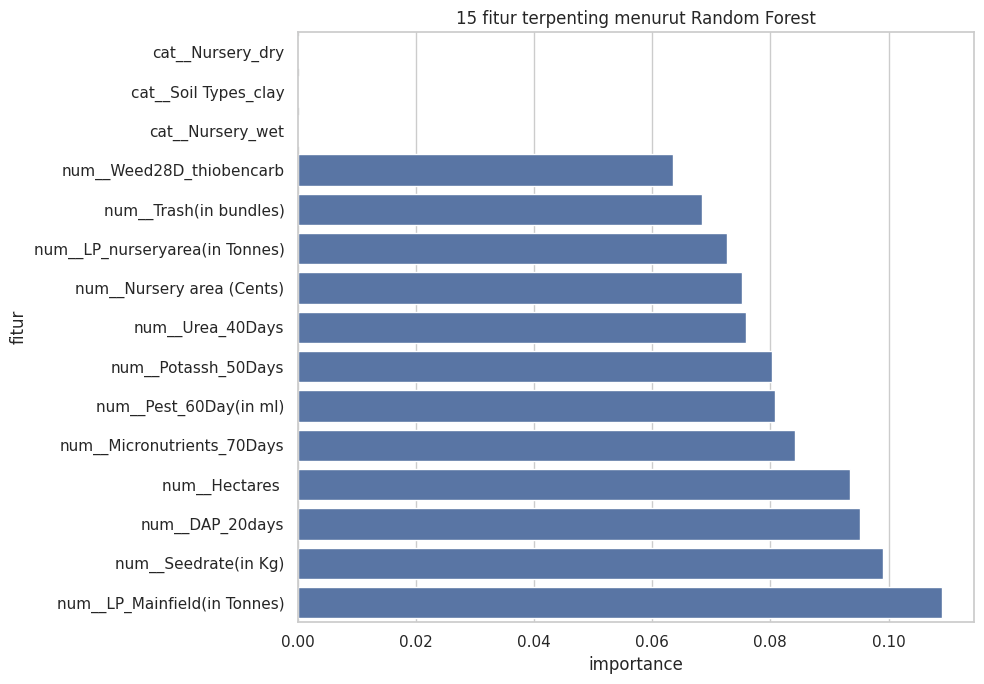

In [12]:
fitted_preprocessor = model.named_steps["preprocessing"]
feature_names = fitted_preprocessor.get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "fitur": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(20))
plt.figure(figsize=(10, 7))
top_features = importance_df.head(15).sort_values("importance")
sns.barplot(data=top_features, x="importance", y="fitur", errorbar=None)
plt.title("15 fitur terpenting menurut Random Forest")
plt.tight_layout()
plt.show()

## 13. Kesimpulan dan langkah lanjutan

**Sesudah seluruh notebook dijalankan**, gunakan metrik evaluasi untuk menilai baseline. Jangan hanya melihat R²; perhatikan MAE/RMSE dalam satuan kilogram dan bandingkan dengan model sederhana atau algoritma lain.

Hal yang perlu diperhatikan:
- Dataset ini tidak memiliki missing values pada pemeriksaan awal (jika hasil Anda sama), tetapi imputasi tetap disiapkan agar pipeline lebih tahan terhadap data baru.
- Outlier IQR tidak dihapus otomatis karena nilai ekstrem bisa merupakan kondisi pertanian yang nyata.
- Pastikan fitur yang dipakai memang tersedia pada saat prediksi dilakukan. Fitur yang baru diketahui setelah panen dapat menyebabkan *data leakage* untuk penggunaan prediksi sebelum panen.
- Uji model lain (misalnya Gradient Boosting), lakukan cross-validation, dan evaluasi pada periode/lokasi berbeda sebelum dipakai untuk keputusan pertanian.
- Hasil ini menunjukkan pola prediksi dari dataset, bukan rekomendasi agronomi atau jaminan hasil panen.

# 14. Tahap Development Model

Pada tahap ini, model baseline dari tahap modelling dikembangkan agar lebih siap digunakan. Kegiatan yang dilakukan:
1. Membandingkan baseline dengan model sederhana sebagai pembanding.
2. Mencari kombinasi hyperparameter Random Forest yang lebih baik menggunakan cross-validation.
3. Mengevaluasi model terpilih pada data uji yang sama.
4. Menyimpan model, metrik, dan contoh hasil prediksi agar dapat digunakan kembali.

**Catatan:** pencarian parameter dilakukan hanya pada data latih. Data uji tetap disimpan untuk evaluasi akhir agar tidak ikut memengaruhi pemilihan model.

In [13]:
# 14.1 Baseline pembanding dan pencarian hyperparameter
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
import joblib
import json

# Baseline sederhana: selalu memprediksi rata-rata target data latih
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)

# Gunakan pipeline preprocessing + Random Forest yang sudah dibuat sebelumnya.
# Pencarian dilakukan pada data latih saja (3-fold cross-validation).
param_distributions = {
    "regressor__n_estimators": [200, 300, 400],
    "regressor__max_depth": [None, 10, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [1.0, "sqrt"]
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
search.fit(X_train, y_train)

best_model = search.best_estimator_
best_pred = best_model.predict(X_test)

print("Pencarian hyperparameter selesai.")
print("Parameter terbaik:")
print(search.best_params_)
print(f"MAE CV terbaik (Kg): {-search.best_score_:,.2f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Pencarian hyperparameter selesai.
Parameter terbaik:
{'regressor__n_estimators': 200, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 4, 'regressor__max_features': 'sqrt', 'regressor__max_depth': None}
MAE CV terbaik (Kg): 621.66


## 14.2 Evaluasi hasil development

MAE dan RMSE dinyatakan dalam kilogram. R² mengukur seberapa baik model menjelaskan variasi target. Bandingkan hasil model hasil tuning dengan baseline rata-rata dan model Random Forest awal.

In [14]:
def calculate_metrics(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE (Kg)": mean_absolute_error(actual, predicted),
        "RMSE (Kg)": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

development_metrics = pd.DataFrame([
    calculate_metrics(y_test, dummy_pred, "Baseline: rata-rata"),
    calculate_metrics(y_test, y_pred, "Random Forest awal"),
    calculate_metrics(y_test, best_pred, "Random Forest hasil tuning")
]).sort_values("MAE (Kg)").reset_index(drop=True)

display(development_metrics.round(3))
print("Model dengan MAE terkecil pada data uji:",
      development_metrics.iloc[0]["Model"])

,Model,MAE (Kg),RMSE (Kg),R2
0,Random Forest hasil tuning,673.365,934.719,0.990
1,Random Forest awal,685.839,952.581,0.989
2,Baseline: rata-rata,8163.151,9260.569,-0.002


Model dengan MAE terkecil pada data uji: Random Forest hasil tuning


## 14.3 Simpan model dan hasil development

Model terbaik hasil pencarian disimpan sebagai file `.joblib`. File metrik, parameter terbaik, dan prediksi data uji juga diekspor agar dapat diperiksa atau digunakan untuk laporan.

In [15]:
output_dir = Path("development_output")
output_dir.mkdir(exist_ok=True)

model_file = output_dir / "paddy_yield_random_forest.joblib"
metrics_file = output_dir / "development_metrics.csv"
predictions_file = output_dir / "development_predictions.csv"
metadata_file = output_dir / "model_metadata.json"

joblib.dump(best_model, model_file)
development_metrics.to_csv(metrics_file, index=False)

development_predictions = pd.DataFrame({
    "Aktual (Kg)": y_test.to_numpy(),
    "Prediksi (Kg)": best_pred
})
development_predictions["Error absolut (Kg)"] = (
    development_predictions["Aktual (Kg)"] - development_predictions["Prediksi (Kg)"]
).abs()
development_predictions.to_csv(predictions_file, index=False)

metadata = {
    "target": target,
    "model": "RandomForestRegressor dalam Pipeline preprocessing",
    "best_parameters": search.best_params_,
    "best_cv_mae_kg": float(-search.best_score_),
    "test_rows": int(len(y_test)),
    "features": list(X.columns)
}
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("File berhasil disiapkan:")
for path in [model_file, metrics_file, predictions_file, metadata_file]:
    print("-", path.resolve())

File berhasil disiapkan:
- /content/development_output/paddy_yield_random_forest.joblib
- /content/development_output/development_metrics.csv
- /content/development_output/development_predictions.csv
- /content/development_output/model_metadata.json


## 14.4 Uji penggunaan model tersimpan pada satu data baru

Bagian ini memuat kembali file model yang disimpan, lalu memprediksi satu baris dari data uji sebagai simulasi input baru. Baris ini hanya untuk demonstrasi pemakaian; evaluasi performa tetap menggunakan seluruh data uji.

In [16]:
loaded_model = joblib.load(model_file)

# Simulasi satu input baru: satu baris fitur dari data uji, tanpa kolom target
sample_input = X_test.iloc[[0]].copy()
sample_prediction = loaded_model.predict(sample_input)[0]

print("Contoh input untuk prediksi:")
display(sample_input)
print(f"Prediksi hasil panen: {sample_prediction:,.2f} Kg")
print(f"Nilai aktual pada contoh (untuk pembanding): {float(y_test.iloc[0]):,.2f} Kg")

# Fungsi praktis: berikan DataFrame dengan kolom fitur yang sama seperti X
def prediksi_hasil_padi(data_baru):
    kolom_wajib = list(X.columns)
    kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in data_baru.columns]
    if kolom_hilang:
        raise ValueError(f"Kolom fitur belum lengkap: {kolom_hilang}")
    return loaded_model.predict(data_baru[kolom_wajib])

print("Fungsi prediksi_hasil_padi(data_baru) siap digunakan.")

Contoh input untuk prediksi:


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles)
637,5,Kurinjipadi,ponmani,alluvial,125,62.5,wet,100,5,200,10,135.65,51.9,75,3000,19.6,20.4,187.2,270.8,167.0,250.0,61.0,64.0,19.5,34,18.5,35,17.0,32.5,16.0,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,500


Prediksi hasil panen: 30,686.88 Kg
Nilai aktual pada contoh (untuk pembanding): 31,555.00 Kg
Fungsi prediksi_hasil_padi(data_baru) siap digunakan.


## 14.5 Kesimpulan tahap development

Setelah seluruh sel berhasil dijalankan:
- Pilih model berdasarkan metrik evaluasi, terutama MAE/RMSE dan R², bukan hanya nama algoritmanya.
- Pastikan file model dan CSV hasil evaluasi muncul di folder `development_output`.
- Catat nilai metrik aktual dari hasil eksekusi notebook untuk laporan.
- Sebelum model digunakan untuk prediksi sebelum panen, tinjau kembali fitur yang dipakai. Kolom seperti `LP_Mainfield(in Tonnes)` mungkin hanya diketahui setelah panen; fitur yang belum tersedia pada waktu prediksi dapat menyebabkan data leakage.
- Hasil prediksi adalah estimasi berdasarkan pola dataset, bukan jaminan hasil panen nyata.